# Counterfactual Sampling on CelebA: DR-CPME Target, Riesz MMD Flow (AdamW), Male Arm, n = 16384

Doubly robust counterfactual face sampling on the CelebA attribute-rebalancing design (Dance et
al., 2026, Section 5.4; see `dgp_analysis/CelebA.ipynb` for the verified construction). The
interventional law $P(Y(1))$ is represented by its cross-fitted doubly robust mean embedding
over frozen SD-VAE latents of the logged faces, and samples are generated by minimising the
weighted Riesz energy distance with AdamW over the particle latents. The male arm
($a^\* = 1$) must move its blond fraction upward toward the balanced interventional
mixture; the female notebook is the matched counterpart with an identical configuration.

This is the **observation-count ablation** of the male-arm notebook: the identical
pipeline at $n = 16384$ logged observations (vs $2048$) with the same $2000$ references.
Unlike the female ablation, the particle count also changes here as a direct consequence
of more data: the arm grows past the cap, so $M = 1024$ instead of the $922$ available at
$n = 2048$. This is the arm where the $n = 2048$ flow did **not** reach the reference
floor, so it is the arm where more observations could show a genuine gain.

In [1]:
import sys
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import binary_stats, load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit_nystrom,
                             make_crossfit_fold_ids, select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import CleanFIDScorer, LegacyFIDScorer, sliced_wasserstein
from kernel_utils import RBF

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data

Controlled observational sample ($n = 16384$ at $256 \times 256$; $A = \mathrm{Male}$,
$X = \mathrm{BlondHair}$, prescribed $P(X{=}1) = 0.3$, $P(A{=}1|X{=}0) = 0.6$,
$P(A{=}1|X{=}1) = 0.1$) plus 2000 held-out balanced reference images per interventional arm (the evaluation construction of Dance et al., 2026, App. B.3),
drawn disjointly from the same pool. The observed male arm has blond fraction
$\approx 0.07$; the interventional mixture is $0.30$.

In [2]:
TARGET_A = 1
CACHE = "../../data/celeba_dgp/celeba_paper_256_n16384_nref2000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=256,
                         n_obs=16384, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
Y_ref = data[f"Y{TARGET_A}_ref"]
stats = binary_stats(A, X)
arm = A == TARGET_A
print(f"n = {stats['n']}   cells (A,X) = { {k: v for k, v in sorted(stats['cells'].items())} }")
print(f"arm a={TARGET_A} size = {int(arm.sum())}   observed blond fraction "
      f"E[X|A={TARGET_A}] = {X[arm].float().mean():.3f}   (interventional marginal 0.300)")

n = 16384   cells (A,X) = {(0, 0): 4587, (0, 1): 4424, (1, 0): 6881, (1, 1): 492}
arm a=1 size = 7373   observed blond fraction E[X|A=1] = 0.067   (interventional marginal 0.300)


## 2. SD-VAE Latents

A frozen pretrained VAE (`stabilityai/sd-vae-ft-mse`) supplies the latent space: the encoder maps
each face to a flattened $4 \times 32 \times 32 = 4096$-dimensional code and the decoder maps
transported latents back to faces. Latents are standardised per coordinate so the isotropic energy
kernel treats all coordinates comparably.

In [3]:
vae = load_sd_vae(device)
Z = encode_images(vae, Y)
Z_ref = encode_images(vae, Y_ref)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: (z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
Z_std, Z_ref_std = to_flow(Z), to_flow(Z_ref)
print(f"latents: {tuple(Z.shape)}, standardised per coordinate")

/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


latents: (16384, 4096), standardised per coordinate


## 3. Cross-Fitted DR Weights

The target embedding is $\hat\chi(1) = \sum_i v_i\, k_Y(z_i, \cdot)$ over all logged latents,
with the cross-fitted one-step DR weights on one shared 5-fold split (out-of-fold logistic
propensity, conditional mean embedding, and per-fold ridge). Both $X$ and $A$ are binary, so their
kernels are delta kernels; with the saturated propensity the construction reduces to cell-wise
post-stratification, and $\sum_i v_i X_i = 0.300$ is an algebraic sanity check rather than
independent evidence.

In [4]:
n = len(A)
fold_ids = make_crossfit_fold_ids(n, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X.double().unsqueeze(1), A.double(), fold_ids)
w_hat = (A == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

# Gram BLOCKS on demand rather than the n x n matrix: at n = 16384 each full Gram is
# 2.1 GB in float64 and every fold a 13107^2 solve. The kernel is discrete here --
# K[i, j] = 1{cell_i == cell_j} over the four (A, X) cells, and
# K_pi[i, j] = 1{x_i == x_j} 1{a_i = a*} -- so the blocks are cheap comparisons.
cell = (A * 2 + X).long()
on_arm_flag = (A == TARGET_A).double()
gram = lambda rows, cols: (cell[rows][:, None] == cell[cols][None, :]).double()
gram_pi = lambda rows, cols: ((X[rows][:, None] == X[cols][None, :]).double()
                              * on_arm_flag[rows][:, None])

fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    # lambda is selected on a 2000-row subsample: the full training block is itself an
    # n^3 solve and the selection does not need it
    pick = train[torch.randperm(len(train),
                                generator=torch.Generator().manual_seed(0))[:2000].numpy()]
    fold_lambdas[int(fold)], _ = select_regularization(gram(pick, pick),
                                                       Z_std[pick, 0].double().cpu(), seed=0)

v_dr = cpme_dr_weights_crossfit_nystrom(
    gram, gram_pi, w_hat, fold_ids, fold_lambdas, n_landmarks=1024,
    generator=torch.Generator().manual_seed(SEED)).float().to(device)
print(f"per-fold lambdas: {fold_lambdas}")
print(f"DR support: all {n} logged rows (Nystrom, 1024 landmarks per fold)")
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}   "
      f"sum(v X) = {(v_dr.cpu() * X.float()).sum():.3f}  (marginal 0.300)")

per-fold lambdas: {0: 10.0, 1: 10.0, 2: 10.0, 3: 10.0, 4: 10.0}
DR support: all 16384 logged rows (Nystrom, 1024 landmarks per fold)
DR weights: sum(v) = 1.000   sum|v| = 1.000   sum(v X) = 0.300  (marginal 0.300)


## 4. Riesz MMD Flow (AdamW, warm-up + cosine decay)

Particles start at $M = \min(1024, n_{\mathrm{arm}})$ observed arm-$a^\*$ latents (the actual
count is printed) and minimise the weighted Riesz energy distance toward
$\hat\chi(1)$ with AdamW: linear warm-up then cosine decay of the learning rate to zero, the
schedule that lets the particle cloud settle. Along the flow, the sliced Wasserstein-2
distance between the particle cloud and the **encoded reference latents** is tracked — the
same yardstick as the final evaluation, computed in latent space from the held-out target
samples, with a reference-split floor for calibration.

M = 2000 particles (arm size 7373)


Riesz flow:   0%|          | 0/4000 [00:00<?, ?it/s]

loss 64.4998 -> 64.3423   mean transport 8.66


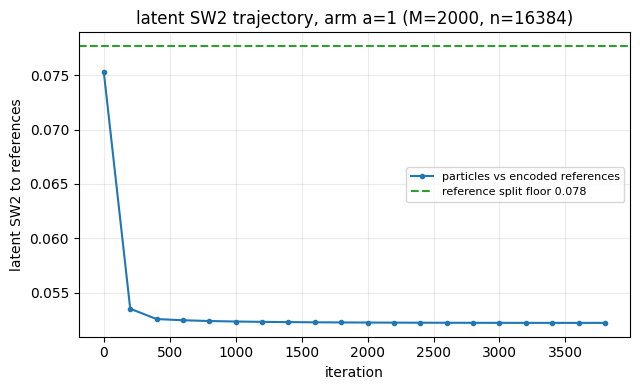

In [5]:
arm_indices = torch.nonzero(arm).ravel()
M = min(2000, len(arm_indices))       # the evaluation protocol's count (Dance et al.)
pick = arm_indices[torch.randperm(len(arm_indices),
                                  generator=torch.Generator().manual_seed(SEED))[:M]]
initial_particles = Z_std[pick].clone()
print(f"M = {M} particles (arm size {len(arm_indices)})")

torch.manual_seed(1)
flow_particles, history = adamw_riesz_flow(
    initial_particles.clone(), Z_std, target_weights=v_dr, sliced=False,
    n_iterations=4000, learning_rate=0.001, warmup_steps=100,
    lr_schedule="cosine", snapshot_every=200, verbose=True)
print(f"loss {history['loss'][0]:.4f} -> {history['loss'][-1]:.4f}   "
      f"mean transport {(flow_particles - initial_particles).norm(dim=1).mean():.2f}")

snap_iters = sorted(history["snapshots"])
snap_sw2 = [sliced_wasserstein(history["snapshots"][it], Z_ref_std, p=2, seed=0).item()
            for it in snap_iters]
latent_floor = sliced_wasserstein(Z_ref_std[:1000], Z_ref_std[1000:], p=2, seed=0).item()
plt.figure(figsize=(6.5, 4))
plt.plot(snap_iters, snap_sw2, marker="o", ms=3, label="particles vs encoded references")
plt.axhline(latent_floor, ls="--", c="tab:green",
            label=f"reference split floor {latent_floor:.3f}")
plt.xlabel("iteration")
plt.ylabel("latent SW2 to references")
plt.title(f"latent SW2 trajectory, arm a={TARGET_A} (M={M}, n={n})")
plt.legend(fontsize=8)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Sampled Faces vs. Starting Faces

Top: decoded starting particles (observed arm). Bottom: the decoded flowed particles — the
sampler's draw from the interventional law. The flow is a distributional sampler with no
per-image anchor, so individual identities may change while the population is rebalanced. The bottom row shows held-out **reference samples** — genuine draws
from the counterfactual distribution $P(Y(a^\*))$ — for visual comparison.

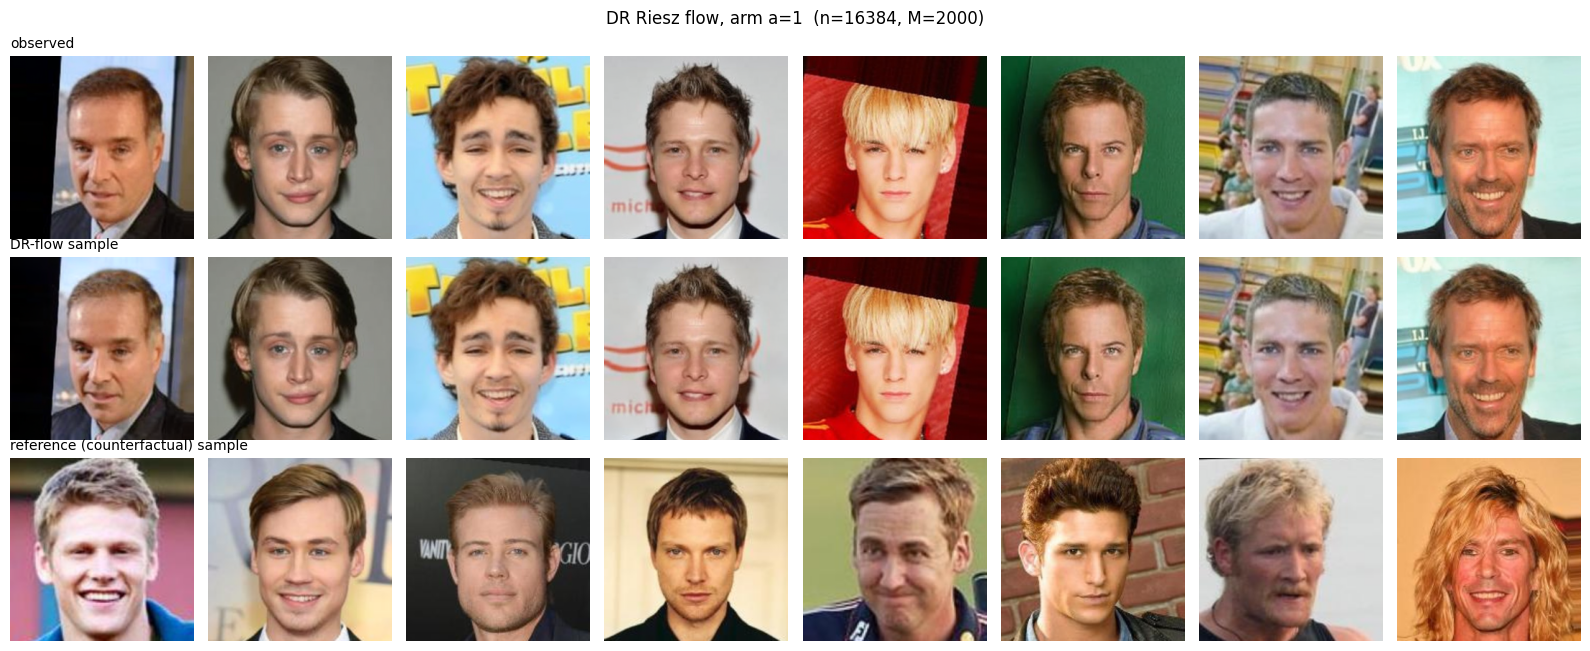

In [6]:
idx, n_show = 24, 8
ref_pick = torch.randperm(len(Y_ref), generator=torch.Generator().manual_seed(2))[:n_show]
with torch.no_grad():
    start_faces = decode_latents(vae, from_flow(initial_particles[idx:idx + n_show]), 256)
    flowed_faces = decode_latents(vae, from_flow(flow_particles[idx:idx + n_show]), 256)
reference_faces = Y_ref[ref_pick]
fig, axes = plt.subplots(3, n_show, figsize=(2.0 * n_show, 6.6))
for column in range(n_show):
    axes[0, column].imshow(to_image_range(start_faces[column]).permute(1, 2, 0).numpy())
    axes[1, column].imshow(to_image_range(flowed_faces[column]).permute(1, 2, 0).numpy())
    axes[2, column].imshow(to_image_range(reference_faces[column]).permute(1, 2, 0).numpy())
    for row in (0, 1, 2):
        axes[row, column].axis("off")
axes[0, 0].set_title("observed", fontsize=10, loc="left")
axes[1, 0].set_title("DR-flow sample", fontsize=10, loc="left")
axes[2, 0].set_title("reference (counterfactual) sample", fontsize=10, loc="left")
fig.suptitle(f"DR Riesz flow, arm a={TARGET_A}  (n={n}, M={M})", fontsize=12)
fig.tight_layout()
plt.show()

## 6. Structural Edits Along the Flow

Each row is one particle, each column a snapshot iteration. The particles shown are those
whose decoded image moves furthest over the run, so the edit is visible: the flow should
change hair colour and leave identity, pose and background alone.

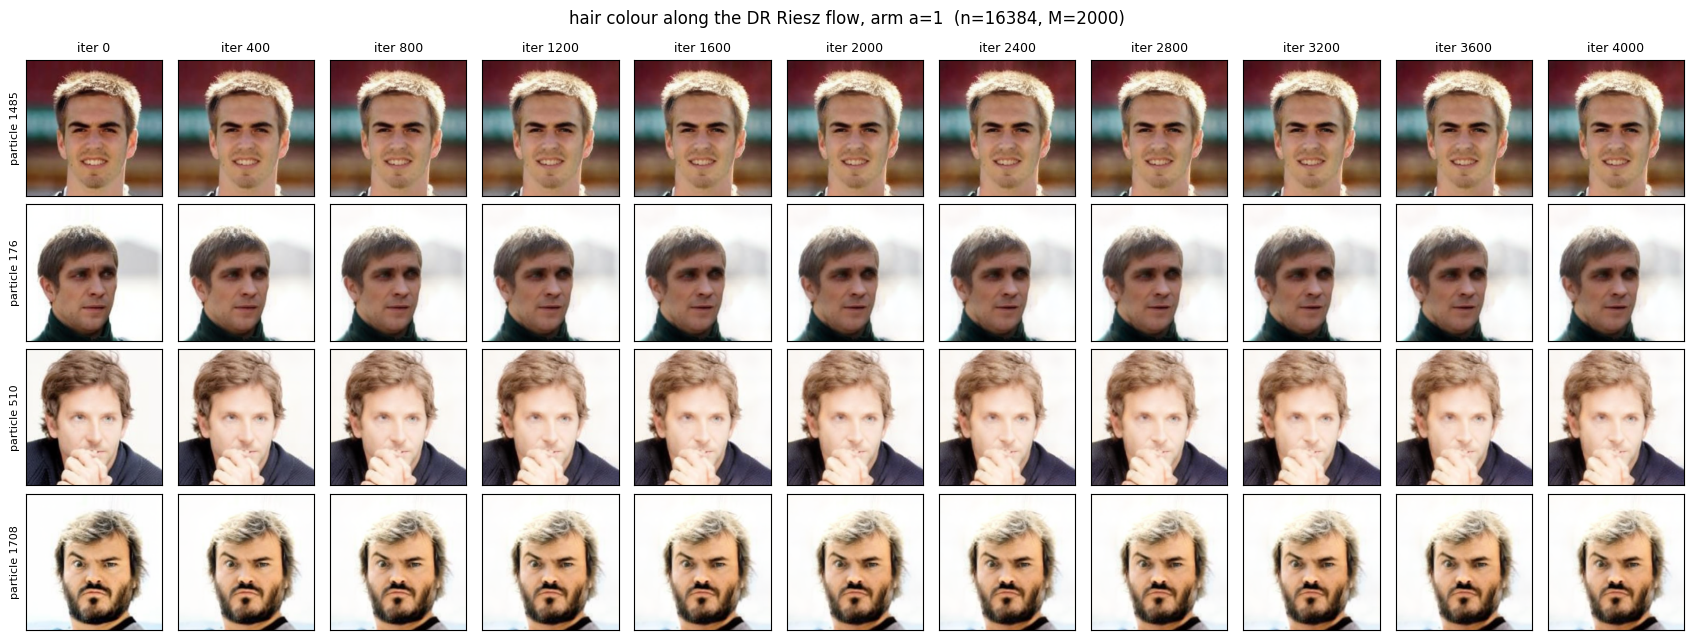

In [7]:
snapshot_iters = [it for it in sorted(history["snapshots"]) if it % 400 == 0]
if snapshot_iters[-1] != 4000:
    snapshot_iters.append(4000)
    history["snapshots"][4000] = flow_particles

moved = (flow_particles - initial_particles).norm(dim=1)
track = torch.topk(moved, 4).indices.tolist()
with torch.no_grad():
    frames = {it: decode_latents(vae, from_flow(history["snapshots"][it][track]), 256)
              for it in snapshot_iters}

fig, axes = plt.subplots(len(track), len(snapshot_iters),
                         figsize=(1.55 * len(snapshot_iters), 1.62 * len(track)))
for row, particle in enumerate(track):
    for column, it in enumerate(snapshot_iters):
        axes[row, column].imshow(to_image_range(frames[it][row]).permute(1, 2, 0).numpy())
        axes[row, column].set_xticks([]); axes[row, column].set_yticks([])
        if row == 0:
            axes[row, column].set_title(f"iter {it}", fontsize=9)
    axes[row, 0].set_ylabel(f"particle {particle}", fontsize=8)
fig.suptitle(f"hair colour along the DR Riesz flow, arm a={TARGET_A}  (n={n}, M={M})",
             fontsize=12)
fig.tight_layout()
plt.show()

## 7. Metric Evaluation

The evaluation follows the protocol of Dance et al. (2026, App. B.3): per intervention
arm, samples are scored against $n_{\mathrm{ref}} = 2000$ held-out reference images of
$P(Y(1))$ by sliced Wasserstein-2 distance in flattened pixel space
(1000 random projections, truncation to the smaller sample), reporting **SW2 (base)** —
the observed arm, the flow's source, against the references — and **SW2 (target)** — the
flowed sample against the references. Beyond that protocol the table adds SW1 and unbiased
squared MMD (median-heuristic RBF) as columns, plus two
diagnostic rows: the VAE round-trip of the observed arm (isolating the decoder — any
improvement beyond it is transport, not smoothing) and a 1000/1000 split of the
references (the finite-sample floor).

Images are stored in $[-1,1]$, the paper's range. The full-resolution numbers still are
not directly comparable with its Figure 4 because the resolution differs ($256 \times 256$
here vs their $64 \times 64$); the $64 \times 64$ block below closes that gap. The
remaining differences are the observational sample size and the fact that this notebook is
a single run (multi-seed aggregation belongs to the simulation scripts). The projections
are seeded for reproducibility.

**$64 \times 64$ evaluation.** To read the numbers against Figure 4 directly, the same
samples and references are area-downsampled to $64 \times 64$ — the figure's resolution;
the $[-1,1]$ pixel range already matches — and re-scored. Downsampling a $256 \times 256$
outcome is statistically equivalent to generating the outcome at $64 \times 64$ (both are
resizes of the same underlying crops), so this comparison needs no separate pipeline. It
remains a single run at $n = 2048$ against the paper's three-seed $n = 20{,}000$ setting.

At this $n$ the observed arm holds $\approx 7400$ images; the metric rows use its first
$2000$ — the truncation size of the sliced-Wasserstein protocol, which makes the SW values
identical to using the full arm and keeps the MMD estimate at the same sample size.

In [8]:
with torch.no_grad():
    flow_images = decode_latents(vae, from_flow(flow_particles), 256)
observed_images = Y[arm_indices[:2000]]
flatten = lambda images: images.reshape(images.shape[0], -1)
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_ref))


def evaluate(images):
    reference = flatten(Y_ref)
    sw2 = sliced_wasserstein(flatten(images), reference, p=2, seed=0).item()
    sw1 = sliced_wasserstein(flatten(images), reference, p=1, seed=0).item()
    mmd2 = squared_mmd(kernel_pixel, flatten(images), reference, unbiased=True).item()
    return sw2, sw1, mmd2


with torch.no_grad():
    roundtrip_images = decode_latents(vae, encode_images(vae, observed_images), 256)
rows = {f"observed arm {TARGET_A} (base)": observed_images,
        "observed arm, VAE round-trip": roundtrip_images,
        "DR Riesz flow (target)": flow_images}
print(f"{'sample':30s} {'SW2':>8s} {'SW1':>8s} {'MMD^2':>10s}")
for name, images in rows.items():
    sw2, sw1, mmd2 = evaluate(images)
    print(f"{name:30s} {sw2:8.4f} {sw1:8.4f} {mmd2:10.2e}")
sw2_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=2, seed=0).item()
sw1_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=1, seed=0).item()
mmd2_f = squared_mmd(kernel_pixel, flatten(Y_ref[:1000]), flatten(Y_ref[1000:]),
                     unbiased=True).item()
print(f"{'reference 1000/1000 floor':30s} {sw2_f:8.4f} {sw1_f:8.4f} {mmd2_f:10.2e}")

to_64 = lambda images: F.interpolate(images, size=64, mode="area").clamp(-1.0, 1.0)
ref_64 = flatten(to_64(Y_ref))
print()
print("64 x 64 evaluation (resolution of Dance et al., 2026, Figure 4):")
print(f"{'sample':30s} {'SW2':>8s} {'SW1':>8s}")
for name, images in rows.items():
    sw2 = sliced_wasserstein(flatten(to_64(images)), ref_64, p=2, seed=0).item()
    sw1 = sliced_wasserstein(flatten(to_64(images)), ref_64, p=1, seed=0).item()
    print(f"{name:30s} {sw2:8.4f} {sw1:8.4f}")
sw2_f64 = sliced_wasserstein(flatten(to_64(Y_ref[:1000])), flatten(to_64(Y_ref[1000:])),
                             p=2, seed=0).item()
sw1_f64 = sliced_wasserstein(flatten(to_64(Y_ref[:1000])), flatten(to_64(Y_ref[1000:])),
                             p=1, seed=0).item()
print(f"{'reference 1000/1000 floor':30s} {sw2_f64:8.4f} {sw1_f64:8.4f}")
scorers = {"legacy": LegacyFIDScorer(device=device, batch_size=32),
           "clean": CleanFIDScorer(device=device, batch_size=32, num_workers=8,
                                   allow_download=False)}
print()
print("FID at 256 px (every row vs the 2000 RAW references; the round-trip row is the")
print("decoder ceiling -- what a perfect latent-space sampler could reach through this VAE):")
print(f"{'sample':30s} {'legacy':>9s} {'clean':>9s}")
for name, images in rows.items():
    scores = []
    for scorer in scorers.values():
        scores.append(scorer.distance_from_features(scorer.features(images),
                                                    scorer.features(Y_ref)))
    print(f"{name:30s} {scores[0]:9.2f} {scores[1]:9.2f}")
floor_scores = [s.distance_from_features(s.features(Y_ref[:1000]), s.features(Y_ref[1000:]))
                for s in scorers.values()]
print(f"{'reference 1000/1000 floor':30s} {floor_scores[0]:9.2f} {floor_scores[1]:9.2f}")
print("(counts differ between rows: the floor is 1000 vs 1000, the others 2000 vs 2000;")
print(" FID is biased upward at smaller counts, so compare rows at equal counts only)")

sample                              SW2      SW1      MMD^2


observed arm 1 (base)            0.0508   0.0385   2.22e-03


observed arm, VAE round-trip     0.0512   0.0388   2.28e-03


DR Riesz flow (target)           0.0271   0.0182  -2.01e-04


reference 1000/1000 floor        0.0394   0.0274  -2.29e-04



64 x 64 evaluation (resolution of Dance et al., 2026, Figure 4):
sample                              SW2      SW1


... (5 outputs left out)

observed arm 1 (base)              11.98     14.17


observed arm, VAE round-trip       12.36     14.88


DR Riesz flow (target)             12.38     15.34


reference 1000/1000 floor          20.84     25.43
(counts differ between rows: the floor is 1000 vs 1000, the others 2000 vs 2000;
 FID is biased upward at smaller counts, so compare rows at equal counts only)


## Summary

*(written after execution)*